# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP (CNN)\n\n[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Alice0602/DS201_Lab2/blob/main/assignments.ipynb)\n

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

## 0. Thiết lập Môi trường & Bộ dữ liệu VinaFood21
Cell này hỗ trợ tự động nhận diện môi trường (**Google Colab**, **Kaggle**, hoặc **Local Machine**). Khi chạy trên Colab/Kaggle, script sẽ tự động cài thư viện và tải dữ liệu từ Google Drive nếu chưa có.


In [ ]:
# 1. Cài đặt thư viện cần thiết khi chạy trên Colab
import os
import sys
import zipfile
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
print(f"Môi trường: {'Google Colab' if IN_COLAB else 'Local Machine'}")

if IN_COLAB:
    !pip install -q transformers scikit-learn matplotlib seaborn gdown

# 2. Tự động tải và giải nén bộ dữ liệu VinaFood21
DATA_DIR = Path("VinaFood21")
if IN_COLAB and not (DATA_DIR / "train").is_dir():
    print("Đang tải dữ liệu VinaFood21 từ Google Drive...")
    !gdown "https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR" -O VinaFood21.zip
    print("Đang giải nén VinaFood21.zip...")
    with zipfile.ZipFile("VinaFood21.zip", "r") as z:
        z.extractall(".")
    print("Giải nén hoàn tất!")

print(f"Đường dẫn dữ liệu: {DATA_DIR.resolve()} | Tồn tại: {(DATA_DIR / 'train').is_dir()}")


Môi trường: Google Colab
Đang tải dữ liệu VinaFood21 từ Google Drive...
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=f70fc315-dad3-4c1f-a44b-744d9170165f
To: /content/VinaFood21.zip
100% 2.71G/2.71G [00:24<00:00, 110MB/s]
Đang giải nén VinaFood21.zip...
Giải nén hoàn tất!
Đường dẫn dữ liệu: /content/VinaFood21 | Tồn tại: True


In [ ]:
# Khai báo thư viện, cố định seed và định nghĩa Data Pipeline
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from PIL import Image
from torchvision import datasets, transforms

def safe_pil_loader(path):
    with open(path, 'rb') as f:
        img = Image.open(f)
        return img.convert('RGBA').convert('RGB')
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch Version :", torch.__version__)
print("Thiết bị sử dụng:", device)

# Chuẩn hoá theo ImageNet (mean và std chuẩn)
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

def build_transforms(img_size, augment=True):
    """Dựng transform: train có augment (nếu bật), val/test không augment"""
    if augment:
        train_tf = transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    else:
        train_tf = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])

    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf

def build_loaders(data_root="VinaFood21", img_size=64, batch_size=32, augment=True, val_ratio=0.1, num_workers=2, seed=42):
    """Tạo train, val, test DataLoader và danh sách classes"""
    root = Path(data_root)
    train_tf, eval_tf = build_transforms(img_size, augment=augment)

    if (root / "val").is_dir():
        train_ds = datasets.ImageFolder(root / "train", transform=train_tf, loader=safe_pil_loader)
        val_ds   = datasets.ImageFolder(root / "val", transform=eval_tf, loader=safe_pil_loader)
        classes  = train_ds.classes
    else:
        full_train = datasets.ImageFolder(root / "train", transform=train_tf, loader=safe_pil_loader)
        full_eval  = datasets.ImageFolder(root / "train", transform=eval_tf, loader=safe_pil_loader)
        g = torch.Generator().manual_seed(seed)
        idx = torch.randperm(len(full_train), generator=g).tolist()
        n_val = int(len(idx) * val_ratio)
        train_ds = Subset(full_train, idx[n_val:])
        val_ds   = Subset(full_eval, idx[:n_val])
        classes  = full_train.classes

    test_ds = datasets.ImageFolder(root / "test", transform=eval_tf, loader=safe_pil_loader)

    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_dl   = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    test_dl  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    return train_dl, val_dl, test_dl, classes


PyTorch Version : 2.11.0+cu130
Thiết bị sử dụng: cuda


In [ ]:
# Khung huấn luyện, đánh giá và vẽ đồ thị dùng chung cho cả 4 bài
def n_params(module, trainable_only=False):
    """Đếm tổng số tham số hoặc chỉ tham số có requires_grad=True"""
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        pred = logits.argmax(dim=1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(dim=1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred

def plot_loss_curve(history, model_name="Mô hình"):
    """Vẽ biểu đồ train loss vs val loss ngay sau khi huấn luyện"""
    epochs = range(1, len(history["train_loss"]) + 1)
    best_ep = int(np.argmin(history["val_loss"])) + 1

    plt.figure(figsize=(7, 3.8))
    plt.plot(epochs, history["train_loss"], "o-", label="Train Loss")
    plt.plot(epochs, history["val_loss"], "s-", label="Val Loss")
    plt.axvline(best_ep, ls="--", color="gray", label=f"Val Loss thấp nhất (Epoch {best_ep})")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.title(f"Đường cong Loss - {model_name}")
    plt.xticks(list(epochs)[::2] if len(epochs) > 5 else list(epochs))
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"-> Epoch có val_loss thấp nhất: {best_ep} | Val Loss = {min(history['val_loss']):.4f}")

def train_model(model, train_dl, val_dl, epochs=20, lr=1e-3, model_name="Mô hình", save_best=True):
    """Vòng lặp huấn luyện chuẩn, tối ưu bằng Adam và lưu checkpoint tốt nhất"""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable_params, lr=lr)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    best_f1 = -1.0
    best_state = None
    total_train_time = 0.0

    print(f"\n===== Bắt đầu huấn luyện: {model_name} =====")
    print(f"Epochs: {epochs} | LR: {lr} | Tham số cần học: {n_params(model, trainable_only=True):,}")
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, yt, yp = evaluate(model, val_dl, criterion, device)
        va_f1 = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)[2]
        elapsed = time.time() - t0
        total_train_time += elapsed

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        history["val_f1"].append(va_f1)

        mark = ""
        if va_f1 > best_f1:
            best_f1 = va_f1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            mark = " *"

        print(f"Epoch {ep:>2}/{epochs} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {va_loss:.4f} Acc: {va_acc:.4f} F1: {va_f1:.4f} | {elapsed:.1f}s{mark}")

    if save_best and best_state is not None:
        model.load_state_dict(best_state)
        print(f"Đã phục hồi trọng số tốt nhất (val macro-F1: {best_f1:.4f})")

    plot_loss_curve(history, model_name=model_name)
    sec_per_epoch = total_train_time / epochs
    return history, sec_per_epoch

def evaluate_test_set(model, test_dl, classes, model_name="Mô hình"):
    """Đánh giá 4 độ đo (Acc, Precision, Recall, F1-macro) và vẽ ma trận nhầm lẫn 21x21"""
    criterion = nn.CrossEntropyLoss()
    test_loss, test_acc, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

    print(f"\n==================== KẾT QUẢ ĐÁNH GIÁ: {model_name} ====================")
    print(f"Test Loss        : {test_loss:.4f}")
    print(f"Accuracy         : {test_acc:.4f}")
    print(f"Precision (macro): {p_macro:.4f}")
    print(f"Recall (macro)   : {r_macro:.4f}")
    print(f"F1-score (macro) : {f1_macro:.4f}")
    print("-" * 72)
    print("Báo cáo chi tiết từng lớp món ăn:")
    print(classification_report(y_true, y_pred, target_names=classes, digits=4, zero_division=0))

    # Vẽ ma trận nhầm lẫn
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thật")
    plt.title(f"Ma trận nhầm lẫn 21x21 - {model_name}")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return {"acc": test_acc, "p": p_macro, "r": r_macro, "f1": f1_macro}


### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

In [ ]:
# 1. Định nghĩa LeNet-5 điều chỉnh cho ảnh màu 64x64 và 21 lớp
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
        # Dò số chiều sau S4 bằng một dummy forward
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)

# Kiểm tra số tham số
lenet_avg = LeNet5(in_ch=3, img=64, num_classes=21, pool="avg")
print("Số chiều sau flatten:", lenet_avg.n_flat)
print("Tổng tham số LeNet-5:", f"{n_params(lenet_avg):,}")
assert lenet_avg.n_flat == 2704, "Số chiều flatten phải là 2704"
assert n_params(lenet_avg) == 339_421, "Tổng tham số LeNet-5 phải là 339,421"
print("Xác nhận kiến trúc và tham số LeNet-5 hoàn toàn khớp với đề bài!")


Số chiều sau flatten: 2704
Tổng tham số LeNet-5: 339,421
Xác nhận kiến trúc và tham số LeNet-5 hoàn toàn khớp với đề bài!



===== Bắt đầu huấn luyện: LeNet-5 (AvgPool) =====
Epochs: 20 | LR: 0.001 | Tham số cần học: 339,421


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train Loss: 2.8112 Acc: 0.1461 | Val Loss: 2.5672 Acc: 0.2102 F1: 0.1158 | 78.9s *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train Loss: 2.5859 Acc: 0.2122 | Val Loss: 2.4641 Acc: 0.2351 F1: 0.1653 | 75.1s *


...

Epoch 18/20 | Train Loss: 1.9245 Acc: 0.4011 | Val Loss: 2.0712 Acc: 0.3635 F1: 0.3317 | 75.6s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | Train Loss: 1.8969 Acc: 0.4097 | Val Loss: 2.0594 Acc: 0.3775 F1: 0.3516 | 76.6s *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | Train Loss: 1.8767 Acc: 0.4170 | Val Loss: 2.0605 Acc: 0.3755 F1: 0.3515 | 75.9s
Đã phục hồi trọng số tốt nhất (val macro-F1: 0.3516)


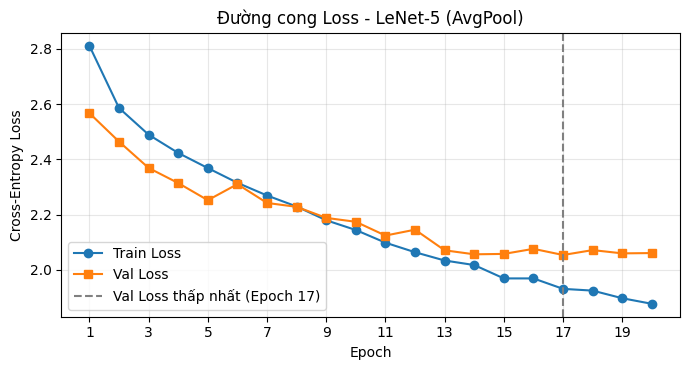

-> Epoch có val_loss thấp nhất: 17 | Val Loss = 2.0535

==================== KẾT QUẢ ĐÁNH GIÁ: LeNet-5 (AvgPool) ====================
Test Loss        : 2.3466
Accuracy         : 0.3041
Precision (macro): 0.2977
Recall (macro)   : 0.2973
F1-score (macro) : 0.2796
------------------------------------------------------------------------
Báo cáo chi tiết từng lớp món ăn:
                  precision    recall  f1-score   support

        banh-can     0.1603    0.1743    0.1670       241
        banh-hoi     0.3437    0.3822    0.3619       607
    banh-mi-chao     0.3344    0.3564    0.3451       289
        banh-tet     0.3828    0.1346    0.1992       364
 banh-trang-tron     0.1557    0.0615    0.0882       309
          banh-u     0.1920    0.1364    0.1595       176
        banh-uot     0.3430    0.2107    0.2611       560
       bap-nuong     0.1642    0.0769    0.1048       143
          bo-kho     0.3632    0.2041    0.2614       338
       bo-la-lot     0.4357    0.5917    0.5019 

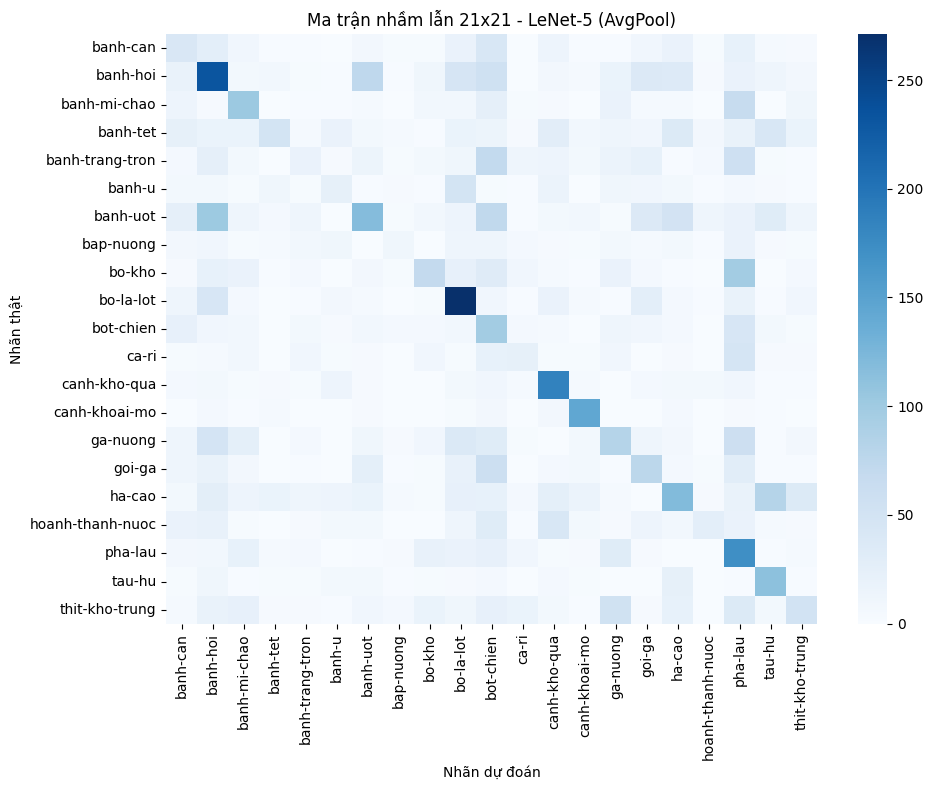

In [ ]:
# 2. Huấn luyện và đánh giá LeNet-5 (AvgPool)
train_dl_64, val_dl_64, test_dl_64, classes = build_loaders(
    data_root=DATA_DIR, img_size=64, batch_size=32, augment=True
)

set_seed(42)
lenet_avg = LeNet5(in_ch=3, img=64, num_classes=len(classes), pool="avg")
hist_lenet_avg, sec_lenet_avg = train_model(
    lenet_avg, train_dl_64, val_dl_64, epochs=20, lr=1e-3, model_name="LeNet-5 (AvgPool)"
)

metrics_lenet_avg = evaluate_test_set(lenet_avg, test_dl_64, classes, model_name="LeNet-5 (AvgPool)")



===== Bắt đầu huấn luyện: LeNet-5 (MaxPool) =====
Epochs: 20 | LR: 0.001 | Tham số cần học: 339,421


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train Loss: 2.8315 Acc: 0.1421 | Val Loss: 2.6085 Acc: 0.1992 F1: 0.1186 | 77.0s *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train Loss: 2.5794 Acc: 0.2149 | Val Loss: 2.4458 Acc: 0.2371 F1: 0.1713 | 75.4s *


...

Epoch 18/20 | Train Loss: 1.8986 Acc: 0.4092 | Val Loss: 2.0910 Acc: 0.3675 F1: 0.3292 | 75.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | Train Loss: 1.8731 Acc: 0.4105 | Val Loss: 2.0158 Acc: 0.3735 F1: 0.3464 | 75.7s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | Train Loss: 1.8747 Acc: 0.4153 | Val Loss: 2.0708 Acc: 0.3825 F1: 0.3475 | 75.6s
Đã phục hồi trọng số tốt nhất (val macro-F1: 0.3597)


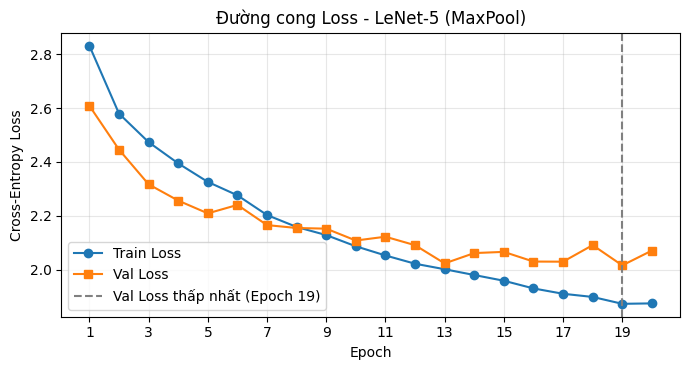

-> Epoch có val_loss thấp nhất: 19 | Val Loss = 2.0158

==================== KẾT QUẢ ĐÁNH GIÁ: LeNet-5 (MaxPool) ====================
Test Loss        : 2.2765
Accuracy         : 0.3150
Precision (macro): 0.3085
Recall (macro)   : 0.2997
F1-score (macro) : 0.2908
------------------------------------------------------------------------
Báo cáo chi tiết từng lớp món ăn:
                  precision    recall  f1-score   support

        banh-can     0.2333    0.0871    0.1269       241
        banh-hoi     0.3586    0.3591    0.3588       607
    banh-mi-chao     0.2427    0.4602    0.3178       289
        banh-tet     0.3913    0.2720    0.3209       364
 banh-trang-tron     0.2123    0.1003    0.1363       309
          banh-u     0.1748    0.1420    0.1567       176
        banh-uot     0.2526    0.3911    0.3069       560
       bap-nuong     0.1081    0.0280    0.0444       143
          bo-kho     0.2411    0.3787    0.2946       338
       bo-la-lot     0.4632    0.6048    0.5246 

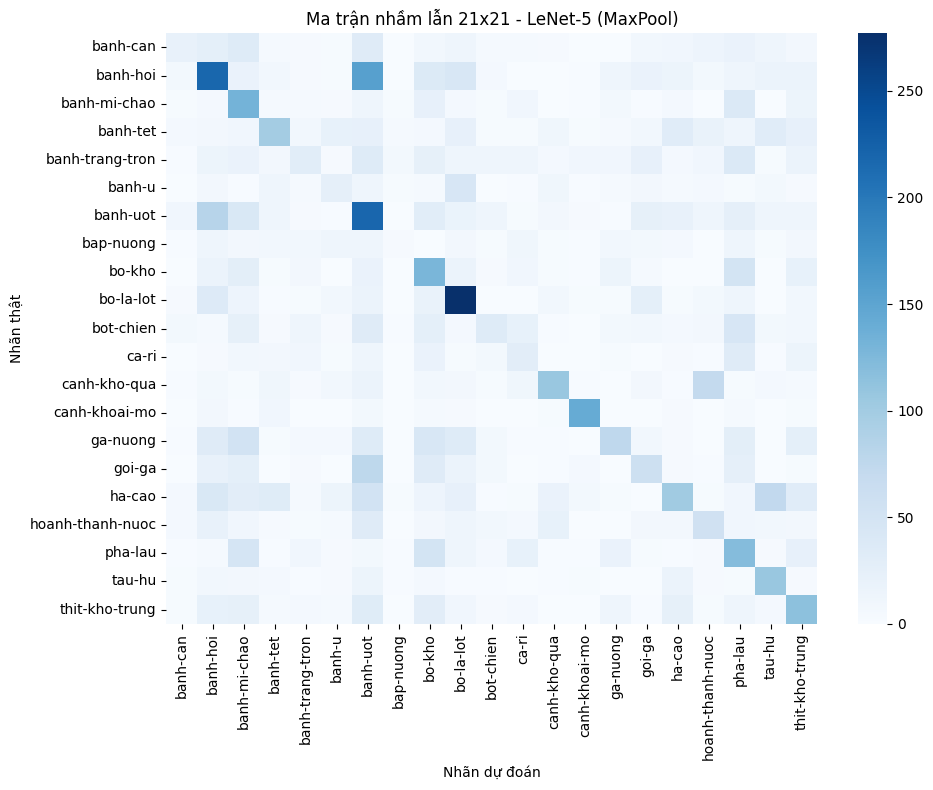


===== SO SÁNH AVGPOOL VS MAXPOOL TRÊN LENET-5 =====
LeNet-5 (AvgPool) Test Macro-F1: 0.2796
LeNet-5 (MaxPool) Test Macro-F1: 0.2908


In [ ]:
# 3. Thử nghiệm so sánh: LeNet-5 với MaxPool2d
set_seed(42)
lenet_max = LeNet5(in_ch=3, img=64, num_classes=len(classes), pool="max")
hist_lenet_max, sec_lenet_max = train_model(
    lenet_max, train_dl_64, val_dl_64, epochs=20, lr=1e-3, model_name="LeNet-5 (MaxPool)"
)

metrics_lenet_max = evaluate_test_set(lenet_max, test_dl_64, classes, model_name="LeNet-5 (MaxPool)")

print("\n===== SO SÁNH AVGPOOL VS MAXPOOL TRÊN LENET-5 =====")
print(f"LeNet-5 (AvgPool) Test Macro-F1: {metrics_lenet_avg['f1']:.4f}")
print(f"LeNet-5 (MaxPool) Test Macro-F1: {metrics_lenet_max['f1']:.4f}")


### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**



**GoogLeNet (Multi-branch Network)**



In [ ]:
# 1. Định nghĩa Inception Block và GoogLeNet rút gọn (3 Inception Blocks)
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        # Nhánh 1: Conv 1x1
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        # Nhánh 2: Conv 1x1 (bottleneck) -> Conv 3x3
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        # Nhánh 3: Conv 1x1 (bottleneck) -> Conv 5x5
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        # Nhánh 4: MaxPool 3x3 -> Conv 1x1
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        # Nối các nhánh theo chiều channel (dim=1)
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

class MiniGoogLeNet(nn.Module):
    def __init__(self, in_ch=3, num_classes=21):
        super().__init__()
        # Stem conv: đưa ảnh 64x64 vào 64 channels
        self.stem = nn.Sequential(
            nn.Conv2d(in_ch, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # [B, 64, 32, 32]
        )
        # Block 1: in_ch=64 -> out_ch = 32 + 48 + 16 + 16 = 112
        self.incept1 = InceptionBlock(64, f1=32, f3r=32, f3=48, f5r=8, f5=16, fp=16)

        # Block 2: in_ch=112 -> out_ch = 64 + 96 + 32 + 32 = 224
        self.incept2 = InceptionBlock(112, f1=64, f3r=64, f3=96, f5r=16, f5=32, fp=32)

        self.pool = nn.MaxPool2d(2, 2)  # [B, 224, 16, 16]

        # Block 3: in_ch=224 -> out_ch = 128 + 160 + 32 + 32 = 352
        self.incept3 = InceptionBlock(224, f1=128, f3r=96, f3=160, f5r=16, f5=32, fp=32)

        # Global Average Pooling + Phân loại
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(352, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.incept1(x)
        x = self.incept2(x)
        x = self.pool(x)
        x = self.incept3(x)
        x = self.gap(x).flatten(1)
        x = self.dropout(x)
        return self.fc(x)

# In số channel và tham số của từng Inception Block
googlenet = MiniGoogLeNet(in_ch=3, num_classes=21)
dummy_x = torch.rand(1, 3, 64, 64)
with torch.no_grad():
    s = googlenet.stem(dummy_x)
    i1 = googlenet.incept1(s)
    i2 = googlenet.incept2(i1)
    p = googlenet.pool(i2)
    i3 = googlenet.incept3(p)

print("===== KIỂM TRA SHAPE & CHANNEL CÁC INCEPTION BLOCKS =====")
print(f"Stem output shape       : {tuple(s.shape)}")
print(f"Inception 1 output shape: {tuple(i1.shape)} | Channels: {i1.shape[1]} | Tham số: {n_params(googlenet.incept1):,}")
print(f"Inception 2 output shape: {tuple(i2.shape)} | Channels: {i2.shape[1]} | Tham số: {n_params(googlenet.incept2):,}")
print(f"Inception 3 output shape: {tuple(i3.shape)} | Channels: {i3.shape[1]} | Tham số: {n_params(googlenet.incept3):,}")
print(f"Tổng tham số GoogLeNet  : {n_params(googlenet):,}")


===== KIỂM TRA SHAPE & CHANNEL CÁC INCEPTION BLOCKS =====
Stem output shape       : (1, 64, 32, 32)
Inception 1 output shape: (1, 112, 32, 32) | Channels: 112 | Tham số: 22,808
Inception 2 output shape: (1, 224, 32, 32) | Channels: 224 | Tham số: 88,112
Inception 3 output shape: (1, 352, 16, 16) | Channels: 352 | Tham số: 212,432
Tổng tham số GoogLeNet  : 332,557



===== Bắt đầu huấn luyện: GoogLeNet =====
Epochs: 20 | LR: 0.001 | Tham số cần học: 332,557


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train Loss: 2.8842 Acc: 0.1162 | Val Loss: 2.6642 Acc: 0.1773 F1: 0.1035 | 75.4s *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train Loss: 2.6416 Acc: 0.1851 | Val Loss: 2.4661 Acc: 0.2351 F1: 0.1600 | 75.5s *


...

Epoch 18/20 | Train Loss: 1.6961 Acc: 0.4706 | Val Loss: 1.6551 Acc: 0.4940 F1: 0.4593 | 76.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | Train Loss: 1.6673 Acc: 0.4780 | Val Loss: 1.6909 Acc: 0.4751 F1: 0.4220 | 75.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | Train Loss: 1.6517 Acc: 0.4826 | Val Loss: 1.6335 Acc: 0.5010 F1: 0.4675 | 75.7s
Đã phục hồi trọng số tốt nhất (val macro-F1: 0.4777)


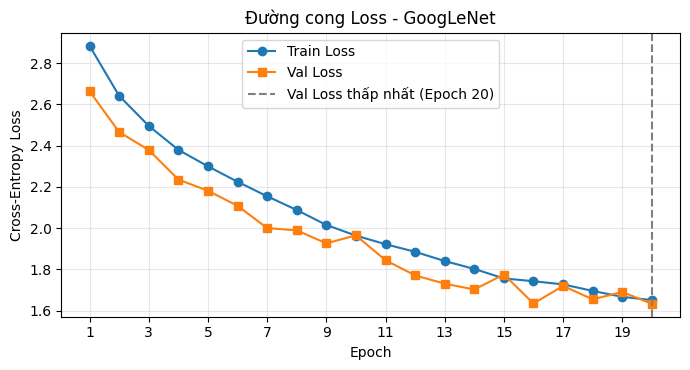

-> Epoch có val_loss thấp nhất: 20 | Val Loss = 1.6335

==================== KẾT QUẢ ĐÁNH GIÁ: GoogLeNet ====================
Test Loss        : 1.8745
Accuracy         : 0.4300
Precision (macro): 0.4287
Recall (macro)   : 0.4090
F1-score (macro) : 0.4053
------------------------------------------------------------------------
Báo cáo chi tiết từng lớp món ăn:
                  precision    recall  f1-score   support

        banh-can     0.2874    0.3029    0.2949       241
        banh-hoi     0.4710    0.6277    0.5381       607
    banh-mi-chao     0.4569    0.3668    0.4069       289
        banh-tet     0.7552    0.3984    0.5216       364
 banh-trang-tron     0.2393    0.1262    0.1653       309
          banh-u     0.4636    0.2898    0.3566       176
        banh-uot     0.3716    0.4161    0.3926       560
       bap-nuong     0.3014    0.1538    0.2037       143
          bo-kho     0.5120    0.3787    0.4354       338
       bo-la-lot     0.5531    0.7620    0.6410       45

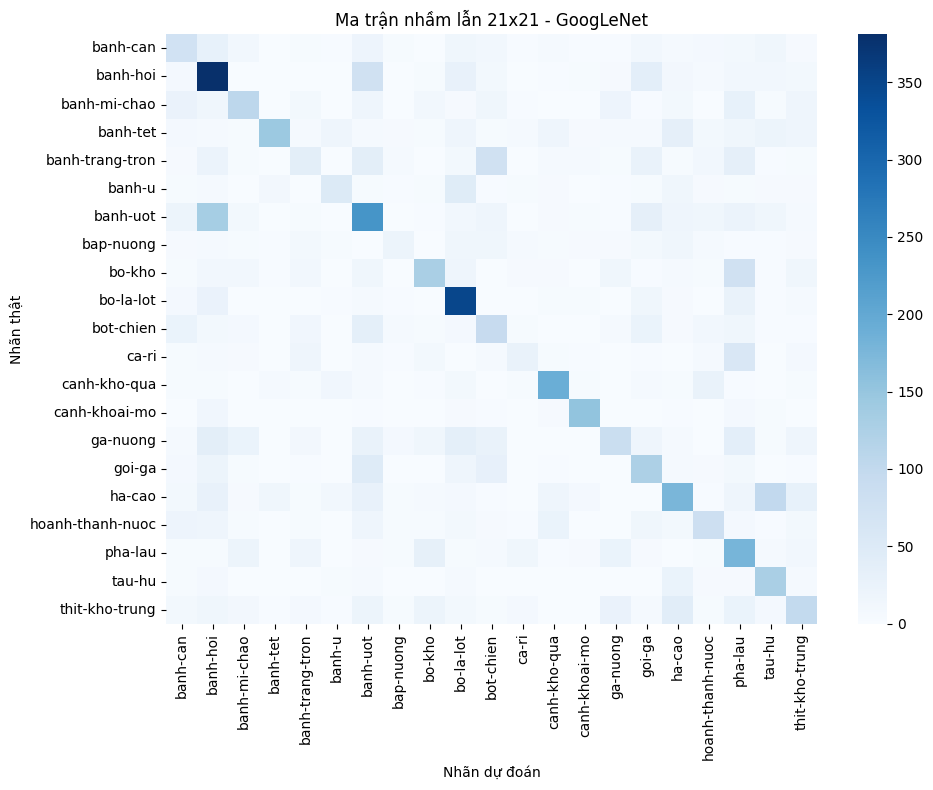

In [ ]:
# 2. Huấn luyện và đánh giá GoogLeNet
set_seed(42)
googlenet = MiniGoogLeNet(in_ch=3, num_classes=len(classes))
hist_googlenet, sec_googlenet = train_model(
    googlenet, train_dl_64, val_dl_64, epochs=20, lr=1e-3, model_name="GoogLeNet"
)

metrics_googlenet = evaluate_test_set(googlenet, test_dl_64, classes, model_name="GoogLeNet")


### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**



**ResNet**



In [ ]:
# 1. Định nghĩa BasicBlock và ResNet-18 [2, 2, 2, 2] từ đầu (from scratch)
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        # Shortcut connection
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)  # Phép cộng residual trước
        return torch.relu(out)        # Kích hoạt ReLU sau

class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1)
        )
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        return nn.Sequential(
            BasicBlock(in_ch, out_ch, stride),
            BasicBlock(out_ch, out_ch, 1)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)

# Kiểm tra số tham số ResNet-18 (phải khớp chính xác 11,187,285 tham số)
r18_check = ResNet18(num_classes=21)
print("Tổng tham số ResNet-18:", f"{n_params(r18_check):,}")
assert n_params(r18_check) == 11_187_285, "Số tham số ResNet-18 phải là 11,187,285"
print("Xác nhận ResNet-18 chuẩn xác hoàn toàn theo giáo trình!")


Tổng tham số ResNet-18: 11,187,285
Xác nhận ResNet-18 chuẩn xác hoàn toàn theo giáo trình!


In [ ]:
# 2. Dataloader cho ResNet-18 (ảnh 96x96) và Huấn luyện LẦN 1: KHÔNG CÓ Augmentation
IMG_SIZE_R18 = 96

# DataLoader KHÔNG có Augmentation
train_dl_r18_noaug, val_dl_r18_noaug, test_dl_r18, _ = build_loaders(
    data_root=DATA_DIR, img_size=IMG_SIZE_R18, batch_size=32, augment=False
)

set_seed(42)
r18_noaug = ResNet18(num_classes=len(classes))
hist_r18_noaug, sec_r18_noaug = train_model(
    r18_noaug, train_dl_r18_noaug, val_dl_r18_noaug, epochs=20, lr=1e-3,
    model_name="ResNet-18 (KHÔNG Augment)"
)

metrics_r18_noaug = evaluate_test_set(r18_noaug, test_dl_r18, classes, model_name="ResNet-18 (KHÔNG Augment)")



===== Bắt đầu huấn luyện: ResNet-18 (KHÔNG Augment) =====
Epochs: 20 | LR: 0.001 | Tham số cần học: 11,187,285


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train Loss: 2.6478 Acc: 0.2014 | Val Loss: 2.7635 Acc: 0.2221 F1: 0.1401 | 73.0s *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train Loss: 2.3365 Acc: 0.2754 | Val Loss: 2.2515 Acc: 0.3058 F1: 0.2523 | 74.8s *


...

Epoch  8/20 | Train Loss: 1.1378 Acc: 0.6330 | Val Loss: 2.0300 Acc: 0.4343 F1: 0.4021 | 73.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  9/20 | Train Loss: 0.8398 Acc: 0.7287 | Val Loss: 2.1783 Acc: 0.4392 F1: 0.4215 | 74.1s *


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 10/20 | Train Loss: 0.5395 Acc: 0.8281 | Val Loss: 2.2242 Acc: 0.4482 F1: 0.4354 | 74.4s *


In [ ]:
# 3. Huấn luyện LẦN 2: CÓ Augmentation
# DataLoader CÓ Augmentation
train_dl_r18_aug, val_dl_r18_aug, _, _ = build_loaders(
    data_root=DATA_DIR, img_size=IMG_SIZE_R18, batch_size=32, augment=True
)

set_seed(42)
r18_aug = ResNet18(num_classes=len(classes))
hist_r18_aug, sec_r18_aug = train_model(
    r18_aug, train_dl_r18_aug, val_dl_r18_aug, epochs=20, lr=1e-3,
    model_name="ResNet-18 (CÓ Augment)"
)

metrics_r18_aug = evaluate_test_set(r18_aug, test_dl_r18, classes, model_name="ResNet-18 (CÓ Augment)")


In [ ]:
# 4. So sánh đường Loss & Phân tích hiện tượng Overfitting của ResNet-18
epochs_r18 = range(1, len(hist_r18_noaug["train_loss"]) + 1)

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(epochs_r18, hist_r18_noaug["train_loss"], "o--", label="Train Loss (Không Augment)")
plt.plot(epochs_r18, hist_r18_noaug["val_loss"], "s-", label="Val Loss (Không Augment)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Lần 1: Không có Augmentation (Bị Overfitting)")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_r18, hist_r18_aug["train_loss"], "o--", label="Train Loss (Có Augment)", color="green")
plt.plot(epochs_r18, hist_r18_aug["val_loss"], "s-", label="Val Loss (Có Augment)", color="red")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Lần 2: Có Augmentation (Giảm Overfitting)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n===== SO SÁNH RESNET-18: CÓ VS KHÔNG AUGMENTATION =====")
print(f"KHÔNG Augmentation -> Test Macro-F1: {metrics_r18_noaug['f1']:.4f}")
print(f"CÓ Augmentation    -> Test Macro-F1: {metrics_r18_aug['f1']:.4f}")
print(f"Chênh lệch Macro-F1 : {metrics_r18_aug['f1'] - metrics_r18_noaug['f1']:+.4f}")
print("""
Nhận xét:
1. Khi KHÔNG có Augmentation: ResNet-18 có tới 11.18 triệu tham số trong khi tập dữ liệu nhỏ (~14k ảnh),
   dẫn đến đường Train Loss giảm mạnh về gần 0 nhưng Val Loss lại bật tăng (Overfitting nghiêm trọng).
2. Khi CÓ Augmentation: Các phép biến đổi xoay, lật, cắt ngẫu nhiên tạo thêm dữ liệu đa dạng, giúp mô hình
   học các đặc trưng khái quát hóa tốt hơn, kìm hãm Val Loss và tăng Macro-F1 rõ rệt.
""")


### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

In [ ]:
# 1. Định nghĩa PretrainedResnet sử dụng microsoft/resnet-50 từ HuggingFace
from transformers import ResNetForImageClassification

class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes, bias=True)
        if freeze_backbone:
            # Đóng băng backbone cho chế độ Feature Extraction
            for p in self.resnet.parameters():
                p.requires_grad = False

    def forward(self, images):
        features = self.resnet(images).pooler_output  # [B, 2048, 1, 1]
        features = features.squeeze(-1).squeeze(-1)   # [B, 2048]
        return self.classifier(features)              # [B, 21]

# Kiểm tra số tham số trong 2 chế độ
fe_test = PretrainedResnet(21, freeze_backbone=True)
ft_test = PretrainedResnet(21, freeze_backbone=False)

print(f"{'Chế độ':<22}{'Tổng tham số':>16}{'Cần cập nhật':>16}{'Learning Rate':>14}")
print(f"{'Feature Extraction':<22}{n_params(fe_test):>16,}{n_params(fe_test, True):>16,}{'1e-3':>14}")
print(f"{'Fine-Tuning':<22}{n_params(ft_test):>16,}{n_params(ft_test, True):>16,}{'1e-4':>14}")

assert n_params(fe_test) == 23_551_061
assert n_params(fe_test, trainable_only=True) == 43_029, "Feature Extraction chỉ cập nhật 43,029 tham số của classifier"
assert n_params(ft_test, trainable_only=True) == 23_551_061, "Fine-tuning cập nhật toàn bộ 23.5M tham số"
print("Kiểm tra tham số ResNet-50 hoàn tất!")


In [ ]:
# 2. Huấn luyện ResNet-50 Pretrained (ảnh 224x224)
IMG_SIZE_R50 = 224

train_dl_224, val_dl_224, test_dl_224, _ = build_loaders(
    data_root=DATA_DIR, img_size=IMG_SIZE_R50, batch_size=32, augment=True
)

# Chế độ 1: Feature Extraction (đóng băng backbone, Adam lr=1e-3)
print("\n==================== CHẾ ĐỘ 1: FEATURE EXTRACTION ====================")
set_seed(42)
r50_fe = PretrainedResnet(num_classes=len(classes), freeze_backbone=True)
hist_r50_fe, sec_r50_fe = train_model(
    r50_fe, train_dl_224, val_dl_224, epochs=15, lr=1e-3, model_name="ResNet-50 (Feature Extraction)"
)
metrics_r50_fe = evaluate_test_set(r50_fe, test_dl_224, classes, model_name="ResNet-50 (Feature Extraction)")

# Chế độ 2: Fine-Tuning (mở toàn bộ mạng, Adam lr=1e-4)
print("\n==================== CHẾ ĐỘ 2: FINE-TUNING ====================")
set_seed(42)
r50_ft = PretrainedResnet(num_classes=len(classes), freeze_backbone=False)
hist_r50_ft, sec_r50_ft = train_model(
    r50_ft, train_dl_224, val_dl_224, epochs=10, lr=1e-4, model_name="ResNet-50 (Fine-Tuning)"
)
metrics_r50_ft = evaluate_test_set(r50_ft, test_dl_224, classes, model_name="ResNet-50 (Fine-Tuning)")


## Bảng Tổng hợp Kết quả Thực nghiệm & Hướng dẫn Nộp bài


In [ ]:
# Bảng tổng hợp kết quả của cả 4 bài thực hành
import pandas as pd

summary_data = [
    {
        "Mô hình": "LeNet-5 (AvgPool)",
        "Resize": "64x64",
        "Số tham số": f"{n_params(lenet_avg):,}",
        "Giây/epoch": f"{sec_lenet_avg:.1f}s",
        "Accuracy": f"{metrics_lenet_avg['acc']:.4f}",
        "Macro-F1": f"{metrics_lenet_avg['f1']:.4f}"
    },
    {
        "Mô hình": "LeNet-5 (MaxPool)",
        "Resize": "64x64",
        "Số tham số": f"{n_params(lenet_max):,}",
        "Giây/epoch": f"{sec_lenet_max:.1f}s",
        "Accuracy": f"{metrics_lenet_max['acc']:.4f}",
        "Macro-F1": f"{metrics_lenet_max['f1']:.4f}"
    },
    {
        "Mô hình": "GoogLeNet (3 Inception)",
        "Resize": "64x64",
        "Số tham số": f"{n_params(googlenet):,}",
        "Giây/epoch": f"{sec_googlenet:.1f}s",
        "Accuracy": f"{metrics_googlenet['acc']:.4f}",
        "Macro-F1": f"{metrics_googlenet['f1']:.4f}"
    },
    {
        "Mô hình": "ResNet-18 (from scratch, No Aug)*",
        "Resize": "96x96",
        "Số tham số": f"{n_params(r18_noaug):,}",
        "Giây/epoch": f"{sec_r18_noaug:.1f}s",
        "Accuracy": f"{metrics_r18_noaug['acc']:.4f}",
        "Macro-F1": f"{metrics_r18_noaug['f1']:.4f}"
    },
    {
        "Mô hình": "ResNet-18 (from scratch, Aug)*",
        "Resize": "96x96",
        "Số tham số": f"{n_params(r18_aug):,}",
        "Giây/epoch": f"{sec_r18_aug:.1f}s",
        "Accuracy": f"{metrics_r18_aug['acc']:.4f}",
        "Macro-F1": f"{metrics_r18_aug['f1']:.4f}"
    },
    {
        "Mô hình": "ResNet-50 (Feature Extraction)*",
        "Resize": "224x224",
        "Số tham số": f"{n_params(r50_fe):,} ({n_params(r50_fe, True):,} train)",
        "Giây/epoch": f"{sec_r50_fe:.1f}s",
        "Accuracy": f"{metrics_r50_fe['acc']:.4f}",
        "Macro-F1": f"{metrics_r50_fe['f1']:.4f}"
    },
    {
        "Mô hình": "ResNet-50 (Fine-Tuning)*",
        "Resize": "224x224",
        "Số tham số": f"{n_params(r50_ft):,}",
        "Giây/epoch": f"{sec_r50_ft:.1f}s",
        "Accuracy": f"{metrics_r50_ft['acc']:.4f}",
        "Macro-F1": f"{metrics_r50_ft['f1']:.4f}"
    }
]

df_summary = pd.DataFrame(summary_data)
print("\n" + "="*80)
print("BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM")
print("="*80)
print(df_summary.to_string(index=False))


### Hướng dẫn Commit, Push lên GitHub và Nộp bài

Sau khi hoàn tất chạy notebook trên Colab hoặc máy cá nhân, bạn thực hiện các bước sau để nộp bài:

1. **Lưu notebook có đầy đủ kết quả (Outputs, biểu đồ loss, ma trận nhầm lẫn):**
   - Trên Colab: Vào **File** -> **Save a copy in GitHub** (chọn repository của bạn), hoặc tải file `.ipynb` về máy rồi commit vào repository.
2. **Commit và Push lên GitHub:**
   ```bash
   git add assignments.ipynb
   git commit -m "Complete Lab 2: CNN with LeNet, GoogLeNet, ResNet-18, and ResNet-50"
   git push origin main
   ```
3. **Tạo file nộp bài:**
   - Tạo file text đặt tên là `<MSSV>.txt` (ví dụ `21120000.txt`).
   - Ghi đường link dẫn đến file notebook trên GitHub của bạn vào bên trong file txt (ví dụ: `https://github.com/<username>/<repo>/blob/main/assignments.ipynb`).
   - Nộp file `<MSSV>.txt` này lên hệ thống khóa học (Courses).
